## Simple Linear Regression Model

In [1]:
import pandas as pd
df = pd.read_csv('Salary_dataset.csv')
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


### Visualization

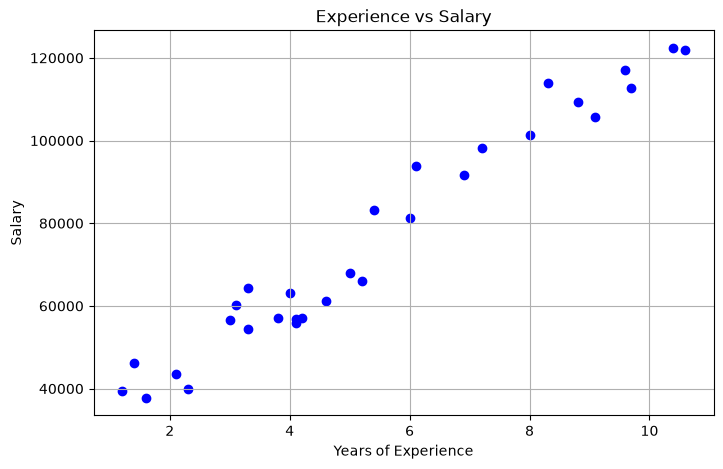

In [2]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.scatter(df['YearsExperience'],df['Salary'],color='blue')
plt.title('Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.grid(True)
plt.show()

X and Y

In [3]:
X=df[['YearsExperience']]
Y=df['Salary']

In [4]:
print('X shape:', X.shape)
print('y shape:', Y.shape)

X shape: (30, 1)
y shape: (30,)


In [5]:
print('X', X.head(), '\n Y', Y.head())

X    YearsExperience
0              1.2
1              1.4
2              1.6
3              2.1
4              2.3 
 Y 0    39344.0
1    46206.0
2    37732.0
3    43526.0
4    39892.0
Name: Salary, dtype: float64


### Train-Test Split

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape[0])
print('Test size :', X_test.shape[0])

Train size: 24
Test size : 6


# fit linear regression model

In [7]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
# # convert X_train to 2D array
# X_train = X_train.values.reshape(-1, 1)
model.fit(X_train,Y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9423.82]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.438e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
print('Intercept (b0):', model.intercept_)
print('Slope (b1)    :', model.coef_[0])

Intercept (b0): 24380.20147947369
Slope (b1)    : 9423.81532303098


### Prediction

In [9]:
Y_pred = model.predict(X_test)
# Generate new table using the dictionary
results = pd.DataFrame({
    'Experience': X_test['YearsExperience'],
    'Actual Salary': Y_test,
    'Predicted Salary': Y_pred.round(2)
})
# return the results 
results

,Experience,Actual Salary,Predicted Salary
27,9.7,112636.0,115791.21
15,5.0,67939.0,71499.28
23,8.3,113813.0,102597.87
17,5.4,83089.0,75268.80
8,3.3,64446.0,55478.79
9,3.8,57190.0,60190.70


### evaluate the model


In [10]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae=mean_absolute_error(Y_test,Y_pred)
mse=mean_squared_error(Y_test,Y_pred)
rmse=np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)

In [11]:
print(f'MAE  : {mae:,.2f}')
print(f'MSE  : {mse:,.2f}')
print(f'RMSE : {rmse:,.2f}')
print(f'R2   : {r2:.4f}')

MAE  : 6,286.45
MSE  : 49,830,096.86
RMSE : 7,059.04
R2   : 0.9024


### checking Overfitting

In [12]:
train_r2 = model.score(X_train, Y_train)
test_r2 = model.score(X_test, Y_test)

print(f'Train R2: {train_r2:.4f}')
print(f'Test  R2: {test_r2:.4f}')

Train R2: 0.9645
Test  R2: 0.9024


### Graph of regression line

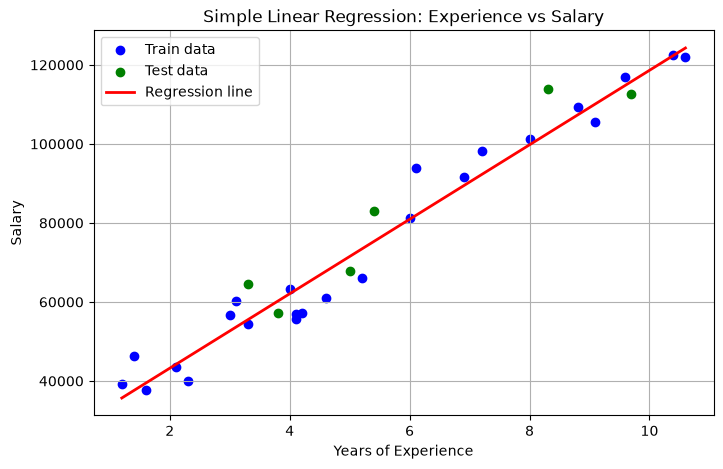

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, Y_train, color='blue', label='Train data')
plt.scatter(X_test, Y_test, color='green', label='Test data')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression line')
plt.title('Simple Linear Regression: Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()